# Lab 2A — 02. Klasyczny detektor bazowy (HSV + kontury + geometria)

Detekcja znaków drogowych i sygnalizatorów oraz rozpoznawanie koloru światła bez użycia sieci neuronowych.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()

from pathlib import Path
from collections import Counter
from dataclasses import dataclass, asdict
import hashlib
import json
import time

import cv2
import numpy as np
import pandas as pd

CLASSES = ('traffic_sign', 'traffic_light')
COLORS = ('red', 'yellow', 'green', 'unknown')


def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8-sig'))


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')


def load_image(path):
    # imdecode obsługuje polskie znaki w ścieżce także na Windows.
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f'Nie można odczytać obrazu: {path}')
    return image


def inventory(root, split='train'):
    """Odczytuje nazwy i rozmiary; niczego nie rozpakowuje ani nie modyfikuje."""
    root = Path(root)
    images = {}
    if split not in ('train', 'val', 'test'):
        raise ValueError(split)
    for folder in sorted((root / 'bdd100k_images_100k').glob(f'**/{split}')):
        for path in folder.glob('*.jpg'):
            images[path.stem] = path
    labels = sorted((root / 'bdd100k_labels').glob(f'**/{split}/*.json'))
    pairs = []
    for label in labels:
        image = images.get(label.stem)
        if image is not None and image.stat().st_size > 0 and label.stat().st_size > 0:
            pairs.append({'id': label.stem, 'image': image.relative_to(root).as_posix(),
                          'label': label.relative_to(root).as_posix()})
    return pairs, {'split': split, 'images': len(images), 'labels': len(labels),
                   'paired': len(pairs), 'unpaired_images': len(images.keys() - {p.stem for p in labels}),
                   'unpaired_labels': len(labels) - len(pairs)}


def annotations(path, shape=None):
    """Format dostarczonej wersji: frames[0].objects; wspiera też listę labels."""
    data = read_json(path)
    frames = data.get('frames', [])
    objects = frames[0].get('objects', []) if frames else data.get('labels', [])
    result, problems = [], Counter()
    for obj in objects:
        category = obj.get('category', '').replace(' ', '_')
        if category not in CLASSES:
            continue
        box = obj.get('box2d')
        if not box:
            problems['missing_box'] += 1
            continue
        try:
            coords = np.array([box[k] for k in ('x1', 'y1', 'x2', 'y2')], float)
        except (KeyError, ValueError, TypeError):
            problems['invalid_box'] += 1
            continue
        if not np.isfinite(coords).all() or coords[2] <= coords[0] or coords[3] <= coords[1]:
            problems['invalid_box'] += 1
            continue
        if shape is not None:
            h, w = shape[:2]
            clipped = np.clip(coords, [0, 0, 0, 0], [w, h, w, h])
            if not np.array_equal(clipped, coords):
                problems['clipped_box'] += 1
            coords = clipped
            if coords[2] <= coords[0] or coords[3] <= coords[1]:
                problems['empty_after_clip'] += 1
                continue
        attrs = obj.get('attributes', {})
        color = attrs.get('trafficLightColor', 'unknown')
        if color not in COLORS:
            color = 'unknown'
        result.append({'class': category, 'box': coords.tolist(),
                       'color': color if category == 'traffic_light' else None,
                       'occluded': bool(attrs.get('occluded', False)),
                       'truncated': bool(attrs.get('truncated', False))})
    return result, data.get('attributes', {}), dict(problems)


def make_manifest(root, output, n=1500, seed=42):
    """Podzbiór oficjalnych train/val/test, w proporcji 70/10/20. Bez mieszania."""
    output = Path(output)
    if output.exists():
        manifest = read_json(output)
        if manifest['seed'] != seed or manifest['n'] != n:
            raise ValueError('Istniejący podział ma inne n/seed. Użyj nowego katalogu eksperymentu.')
        return manifest
    if n < 1000:
        raise ValueError('Polecenie wymaga co najmniej 1000 obrazów.')
    sizes = {'train': int(.7*n), 'val': int(.1*n)}
    sizes['test'] = n-sum(sizes.values())
    splits, counts = {}, {}
    rng = np.random.default_rng(seed)
    for split, size in sizes.items():
        pairs, counts[split] = inventory(root, split)
        if len(pairs) < size:
            raise RuntimeError(f'{split}: za mało par: {len(pairs)} / {size}.')
        order = rng.permutation(len(pairs))[:size]
        splits[split] = [pairs[i] for i in order]
        for item in splits[split]:
            image = load_image(Path(root) / item['image'])
            annotations(Path(root) / item['label'], image.shape)
    all_ids = [r['id'] for records in splits.values() for r in records]
    if len(all_ids) != len(set(all_ids)):
        raise ValueError('Powtórzone identyfikatory między oficjalnymi splitami.')
    manifest = {'seed': seed, 'n': n, 'source': 'official_train_val_test',
                'inventory': counts, 'splits': splits}
    save_json(output, manifest)
    return manifest


def iou(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    wh = np.maximum(0, np.minimum(a[2:], b[2:]) - np.maximum(a[:2], b[:2]))
    inter = float(np.prod(wh))
    union = float(np.prod(a[2:]-a[:2]) + np.prod(b[2:]-b[:2]) - inter)
    return inter / union if union > 0 else 0.


def nms(items, threshold=.35):
    kept = []
    for item in sorted(items, key=lambda x: x['score'], reverse=True):
        if all(item['class'] != old['class'] or iou(item['box'], old['box']) <= threshold for old in kept):
            kept.append(item)
    return kept


@dataclass(frozen=True)
class Params:
    saturation: int = 85
    value: int = 65
    sign_min_area: int = 45
    light_min_area: int = 25
    score_threshold: float = .38
    max_y: float = .85


def masks(image, p):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)
    valid = (s >= p.saturation) & (v >= p.value)
    # OpenCV: H ma zakres 0..179. Czerwony przechodzi przez koniec skali.
    return hsv, {'red': valid & ((h <= 12) | (h >= 165)),
                 'yellow': valid & (h >= 15) & (h <= 38),
                 'green': valid & (h >= 40) & (h <= 95),
                 'blue': valid & (h >= 96) & (h <= 130)}


def contours(mask, close=3):
    mask = np.uint8(mask) * 255
    if close:
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((close, close), np.uint8))
    return cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]


def classify_color(crop, p):
    if crop.size == 0:
        return 'unknown'
    _, mm = masks(crop, p)
    scores = {}
    for color in COLORS[:3]:
        areas = [cv2.contourArea(c) for c in contours(mm[color], close=0)]
        scores[color] = max(areas, default=0.)
    ranking = sorted(scores, key=scores.get, reverse=True)
    best, second = ranking[:2]
    if scores[best] < max(2., crop.shape[0]*crop.shape[1]*.006) or scores[best] < 1.4*scores[second]:
        return 'unknown'
    return best


def detect(image, p=Params()):
    """HSV + kontury + geometria. Wszystkie ramki w oryginalnej skali obrazu."""
    h, w = image.shape[:2]
    hsv, mm = masks(image, p)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    candidates = []
    # Znaki kolorowe oraz jasne tablice (np. ograniczenie prędkości w USA).
    white = (hsv[:, :, 1] < 65) & (hsv[:, :, 2] > 165)
    sign_masks = [mm['red'] | mm['yellow'] | mm['blue'] | mm['green'], white]
    for mask in sign_masks:
        for c in contours(mask):
            x, y, bw, bh = cv2.boundingRect(c)
            area = bw*bh
            if not (p.sign_min_area <= area <= .06*w*h and .35 <= bw/bh <= 3.5 and y < p.max_y*h):
                continue
            fill = cv2.contourArea(c)/area
            hull_area = cv2.contourArea(cv2.convexHull(c))
            solidity = cv2.contourArea(c) / hull_area if hull_area else 0.
            if fill < .4 or solidity < .75:
                continue
            edge = cv2.Canny(gray[y:y+bh, x:x+bw], 70, 150).mean()/255
            if edge < .025:
                continue
            score = float(min(1., .45*fill + .35*min(edge*8, 1) + .2))
            candidates.append({'class': 'traffic_sign', 'box': [x,y,x+bw,y+bh], 'score': score, 'color': None})
    # Obudowy sygnalizatorów: ciemne, zwarte pionowe lub poziome prostokąty.
    dark = gray < 65
    light_boxes = []
    for c in contours(dark):
        x, y, bw, bh = cv2.boundingRect(c)
        if not (p.light_min_area <= bw*bh <= .025*w*h and y < p.max_y*h):
            continue
        ratio = bw/bh
        if not (.18 <= ratio <= .8 or 1.5 <= ratio <= 5.):
            continue
        fill = cv2.contourArea(c)/(bw*bh)
        if fill >= .4:
            light_boxes.append(([x,y,x+bw,y+bh], fill, False))
    # Mała świecąca lampa może nie połączyć się z obudową w masce ciemności.
    # Rozszerzenie to hipoteza geometrii, nie ramka referencyjna.
    # Świecące punkty muszą być jaśniejsze i bardziej nasycone niż zwykły znak.
    lamp_valid = (hsv[:,:,1] >= max(p.saturation,110)) & (hsv[:,:,2] >= 155)
    for color in COLORS[:3]:
        for c in contours(mm[color] & lamp_valid, close=0):
            x,y,bw,bh = cv2.boundingRect(c)
            fill = cv2.contourArea(c)/(bw*bh)
            if 5 <= bw*bh <= 500 and .55 <= bw/bh <= 1.8 and fill >= .45 and y < p.max_y*h:
                for shift in (0., 1., 2.):
                    light_boxes.append(([x-.4*bw,y-shift*bh,x+1.4*bw,y+(3-shift)*bh], .5, True))
    for box, fill, expanded in light_boxes:
        x1,y1,x2,y2 = np.clip(box, [0,0,0,0], [w,h,w,h]).astype(int)
        crop = image[y1:y2,x1:x2]
        if expanded and (crop.size == 0 or np.mean(cv2.cvtColor(crop,cv2.COLOR_BGR2GRAY) < 85) < .35):
            continue
        color = classify_color(crop, p)
        score = float(.25 + .25*fill + (.3 if color != 'unknown' else 0) - (.05 if expanded else 0))
        candidates.append({'class': 'traffic_light', 'box': [int(x1),int(y1),int(x2),int(y2)],
                           'score': score, 'color': color})
    return nms([item for item in candidates if item['score'] >= p.score_threshold])


def match(pred, gt, category, threshold=.5):
    """Greedy po score; jeden GT najwyżej raz. Kolor nie wpływa na dopasowanie."""
    pi = sorted([i for i,p in enumerate(pred) if p['class']==category], key=lambda i: -pred[i]['score'])
    remaining = {i for i,g in enumerate(gt) if g['class']==category}
    matches, fp = [], []
    for i in pi:
        j = max(remaining, key=lambda j: (iou(pred[i]['box'], gt[j]['box']), -j), default=None)
        if j is not None and iou(pred[i]['box'], gt[j]['box']) >= threshold:
            matches.append((i,j))
            remaining.remove(j)
        else:
            fp.append(i)
    return matches, fp, sorted(remaining)


def evaluate(root, records, p, predictions=None):
    rows, errors, color_pairs, saved = [], [], [], {}
    counts = {c: Counter(TP=0, FP=0, FN=0) for c in CLASSES}
    started = time.perf_counter()
    for record in records:
        image = load_image(Path(root)/record['image'])
        gt, _, _ = annotations(Path(root)/record['label'], image.shape)
        pred = predictions[record['id']] if predictions is not None else detect(image, p)
        saved[record['id']] = pred
        for category in CLASSES:
            matched, fp, fn = match(pred, gt, category)
            counts[category].update(TP=len(matched), FP=len(fp), FN=len(fn))
            for pi, gi in matched:
                if category == 'traffic_light':
                    color_pairs.append((gt[gi]['color'], pred[pi]['color']))
            for index in fp:
                errors.append({'id':record['id'], 'type':'FP', 'class':category, 'box':pred[index]['box']})
            for index in fn:
                errors.append({'id':record['id'], 'type':'FN', 'class':category, 'box':gt[index]['box']})
    for category, c in counts.items():
        tp, fp, fn = c['TP'], c['FP'], c['FN']
        rows.append({'class':category, **c, 'precision':tp/(tp+fp) if tp+fp else 0.,
                     'recall':tp/(tp+fn) if tp+fn else 0.,
                     'F1':2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.})
    matrix = pd.DataFrame(0, index=COLORS, columns=COLORS)
    for actual, predicted in color_pairs:
        matrix.loc[actual, predicted] += 1
    return {'metrics':pd.DataFrame(rows), 'confusion':matrix, 'errors':errors, 'predictions':saved,
            'seconds':time.perf_counter()-started, 'matched_lights':len(color_pairs),
            'color_accuracy':sum(a==b for a,b in color_pairs)/len(color_pairs) if color_pairs else None}


def draw(image, boxes, title='', ax=None):
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle
    if ax is None:
        _, ax = plt.subplots(figsize=(14,8))
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    for item in boxes:
        x1,y1,x2,y2 = item['box']
        color = 'lime' if item['class']=='traffic_sign' else 'cyan'
        ax.add_patch(Rectangle((x1,y1), x2-x1,y2-y1,fill=False,edgecolor=color,linewidth=1.3))
        label = item['class'] + (f"/{item['color']}" if item.get('color') else '')
        ax.text(x1,y1,label,color='black',fontsize=6,bbox={'facecolor':color,'alpha':.7,'pad':1})
    ax.set(title=title)
    ax.axis('off')
    return ax


def fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()
N, SEED = 1500, 42
EXP = ROOT/'outputs'/f'official_{N}_seed{SEED}'
manifest = make_manifest(ROOT,EXP/'manifest.json',N,SEED)
assert manifest['source']=='official_train_val_test', 'Użyj manifestu oficjalnych splitów.'
splits = manifest['splits']
print('Podział:',{k:len(v) for k,v in splits.items()})
print('Wyniki:',EXP)

Podział: {'train': 1050, 'val': 150, 'test': 300}
Wyniki: c:\Users\hubi_\Desktop\Dane\Studia\AGH\III sem\Rozpoznawanie wzorców\lab4\outputs\official_1500_seed42


## Kontrola podziału danych

In [2]:
ids = {key:{r['id'] for r in value} for key,value in splits.items()}
assert not (ids['train']&ids['val'] or ids['train']&ids['test'] or ids['val']&ids['test'])
assert sum(map(len,ids.values()))>=1000
print('SHA256 manifestu:',fingerprint(manifest))

SHA256 manifestu: 8c26a9f3f64d011f1e6a5712b593f6076e56927d598783d36617e8ed2c21cf1b


## Wizualizacja masek HSV i detekcji

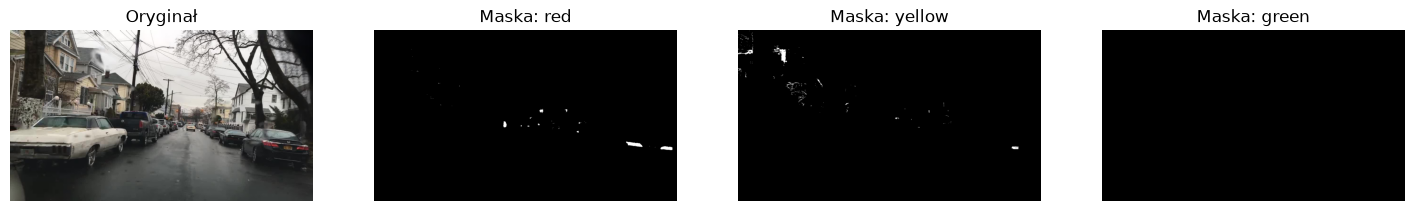

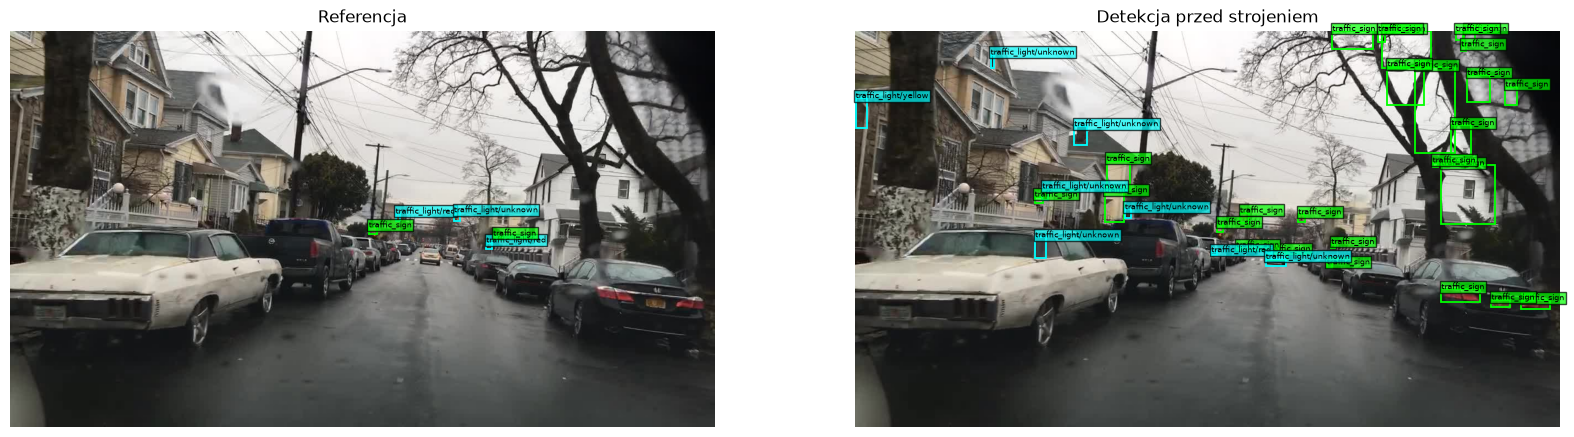

Parametry: {'saturation': 85, 'value': 65, 'sign_min_area': 45, 'light_min_area': 25, 'score_threshold': 0.38, 'max_y': 0.85}


In [3]:
from dataclasses import asdict
record = splits['train'][0]
im = load_image(ROOT / record['image'])
p = Params()
hsv, mm = masks(im, p)
fig, axes = plt.subplots(1, 4, figsize=(18,5))
axes[0].imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); axes[0].set_title('Oryginał')
for ax, name in zip(axes[1:], ['red','yellow','green']):
    ax.imshow(mm[name], cmap='gray'); ax.set_title(f'Maska: {name}')
for ax in axes: ax.axis('off')
plt.show()
gt, _, _ = annotations(ROOT / record['label'], im.shape)
fig, axes = plt.subplots(1,2, figsize=(20,7))
draw(im, gt, 'Referencja', axes[0])
draw(im, detect(im,p), 'Detekcja przed strojeniem', axes[1])
plt.show()
print('Parametry:', asdict(p))

## Metryki detekcji (IoU >= 0.5)

In [4]:
# Małe, znane przykłady weryfikują najważniejszą część oceny.
assert iou([0,0,10,10], [0,0,10,10]) == 1
assert iou([0,0,10,10], [20,20,30,30]) == 0
truth = [{'class':'traffic_light','box':[0,0,10,10], 'color':'red'}]
pred = [{'class':'traffic_light','box':[0,0,10,10], 'score':s, 'color':'green'} for s in [.9,.8]]
matched, fp, fn = match(pred, truth, 'traffic_light')
assert len(matched)==1 and len(fp)==1 and len(fn)==0  # zły kolor nadal jest TP lokalizacji
assert len(match([{'class':'traffic_light','box':[0,0,5,10],'score':1}], truth, 'traffic_light')[0]) == 1
assert len(match([], truth, 'traffic_light')[2]) == 1
print('Testy IoU i dopasowania przeszły.')

Testy IoU i dopasowania przeszły.


## Strojenie parametrów na `val`

In [5]:
from itertools import product
configs = [Params(saturation=s, sign_min_area=a, score_threshold=t)
           for s,a,t in product([65,100], [30,70], [.38,.55])]
results = []
for index, config in enumerate(configs):
    result = evaluate(ROOT, splits['val'], config)
    results.append({'config':index, **asdict(config),
                    'val_macro_F1':float(result['metrics']['F1'].mean())})
    print(f"{index+1}/{len(configs)}: val macro F1 = {results[-1]['val_macro_F1']:.4f}", flush=True)
tuning = pd.DataFrame(results).sort_values(['val_macro_F1','config'], ascending=[False,True])
display(tuning)
EXP.mkdir(parents=True, exist_ok=True)
tuning.to_csv(EXP / 'validation_search.csv', index=False)
best = configs[int(tuning.iloc[0]['config'])]
locked = {'params':asdict(best), 'manifest_sha256':fingerprint(manifest),
          'selection':'maximum validation macro F1; fixed 8 configurations', 'iou':.5}
lock_path = EXP / 'locked_params.json'
if lock_path.exists():
    assert read_json(lock_path) == locked, 'Parametry już zamrożone i różnią się! Nie zmieniaj eksperymentu po teście.'
else:
    save_json(lock_path, locked)
print('Zamrożone parametry:', asdict(best))

1/8: val macro F1 = 0.0175
2/8: val macro F1 = 0.0167
3/8: val macro F1 = 0.0227
4/8: val macro F1 = 0.0220
5/8: val macro F1 = 0.0184
6/8: val macro F1 = 0.0181
7/8: val macro F1 = 0.0239
8/8: val macro F1 = 0.0237


,config,saturation,value,sign_min_area,light_min_area,score_threshold,max_y,val_macro_F1
6,6,100,65,70,25,0.38,0.85,0.023895
7,7,100,65,70,25,0.55,0.85,0.023678
2,2,65,65,70,25,0.38,0.85,0.022738
3,3,65,65,70,25,0.55,0.85,0.022019
4,4,100,65,30,25,0.38,0.85,0.018434
5,5,100,65,30,25,0.55,0.85,0.018118
0,0,65,65,30,25,0.38,0.85,0.017511
1,1,65,65,30,25,0.55,0.85,0.016688


Zamrożone parametry: {'saturation': 100, 'value': 65, 'sign_min_area': 70, 'light_min_area': 25, 'score_threshold': 0.38, 'max_y': 0.85}


## Końcowa ewaluacja na `test`

In [6]:
locked = read_json(EXP / 'locked_params.json')
assert locked['manifest_sha256'] == fingerprint(manifest)
best = Params(**locked['params'])
pred_path = EXP / 'test_predictions.json'
meta = {'manifest_sha256':fingerprint(manifest), 'params':asdict(best),
        'code_sha256':hashlib.sha256(__import__('inspect').getsource(detect).encode()).hexdigest(),
        'coordinates':'original image pixels xyxy',
        'detection_classes':list(CLASSES), 'color_classes':list(COLORS)}
if pred_path.exists():
    cached = read_json(pred_path)
    assert cached['metadata'] == meta, 'Kod, parametry lub podział różnią się od zapisanego eksperymentu.'
    assert set(cached['predictions']) == ids['test']
    final = evaluate(ROOT, splits['test'], best, predictions=cached['predictions'])
else:
    final = evaluate(ROOT, splits['test'], best)
    save_json(pred_path, {'metadata':meta, 'predictions':final['predictions']})
display(final['metrics'].round(4))
print('Sygnalizatory poprawnie zlokalizowane:', final['matched_lights'])
print('Accuracy koloru (tylko TP):', final['color_accuracy'])
print('Czas tej oceny [s]:', round(final['seconds'], 2), '(przy cache pomija detekcję)')
final['metrics'].to_csv(EXP/'test_metrics.csv', index=False)
final['confusion'].to_csv(EXP/'test_color_confusion.csv', index_label='GT / prediction')
save_json(EXP/'test_errors.json', final['errors'])
save_json(EXP/'test_summary.json', {'matched_lights':final['matched_lights'], 'color_accuracy':final['color_accuracy'],
                                  'test_images':len(splits['test']), 'metadata':meta})
print('Predykcje do 2B:', pred_path)

,class,TP,FP,FN,precision,recall,F1
0,traffic_sign,156,5428,821,0.0279,0.1597,0.0476
1,traffic_light,21,2476,763,0.0084,0.0268,0.0128


Sygnalizatory poprawnie zlokalizowane: 21
Accuracy koloru (tylko TP): 0.7619047619047619
Czas tej oceny [s]: 16.82 (przy cache pomija detekcję)
Predykcje do 2B: c:\Users\hubi_\Desktop\Dane\Studia\AGH\III sem\Rozpoznawanie wzorców\lab4\outputs\official_1500_seed42\test_predictions.json


Kolor predykcji,red,yellow,green,unknown
Kolor GT,,,,
red,3,0,0,0
yellow,0,1,0,0
green,0,2,9,0
unknown,0,3,0,3


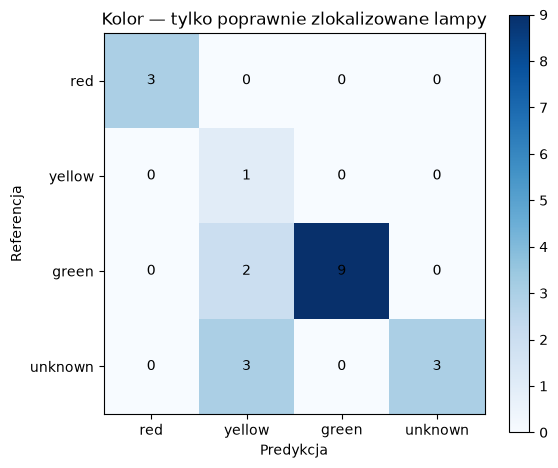

,color,support_matched_GT,precision,recall,F1
0,red,3,1.000000,1.000000,1.000000
1,yellow,1,0.166667,1.000000,0.285714
2,green,11,1.000000,0.818182,0.900000
3,unknown,6,1.000000,0.500000,0.666667


In [7]:
cm = final['confusion']
display(cm.rename_axis(index='Kolor GT', columns='Kolor predykcji'))
fig, ax = plt.subplots(figsize=(6,5))
plot = ax.imshow(cm.values, cmap='Blues')
ax.set(xticks=range(4), yticks=range(4), xticklabels=COLORS, yticklabels=COLORS,
       xlabel='Predykcja', ylabel='Referencja', title='Kolor — tylko poprawnie zlokalizowane lampy')
for i in range(4):
    for j in range(4): ax.text(j,i,str(cm.iloc[i,j]),ha='center',va='center')
fig.colorbar(plot, ax=ax)
plt.tight_layout(); fig.savefig(EXP/'color_confusion.png', dpi=150); plt.show()
color_rows = []
for color in COLORS:
    tp = int(cm.loc[color,color]); support = int(cm.loc[color].sum()); predicted = int(cm[color].sum())
    color_rows.append({'color':color,'support_matched_GT':support,
                       'precision':tp/predicted if predicted else 0.,
                       'recall':tp/support if support else 0.,
                       'F1':2*tp/(support+predicted) if support+predicted else 0.})
color_table = pd.DataFrame(color_rows)
display(color_table)
color_table.to_csv(EXP/'test_color_metrics.csv', index=False)
if final['matched_lights']==0:
    print('Brak TP sygnalizatorów: accuracy koloru jest nieokreślona, a nie równa 100%.')

## Analiza błędów (FP i FN)

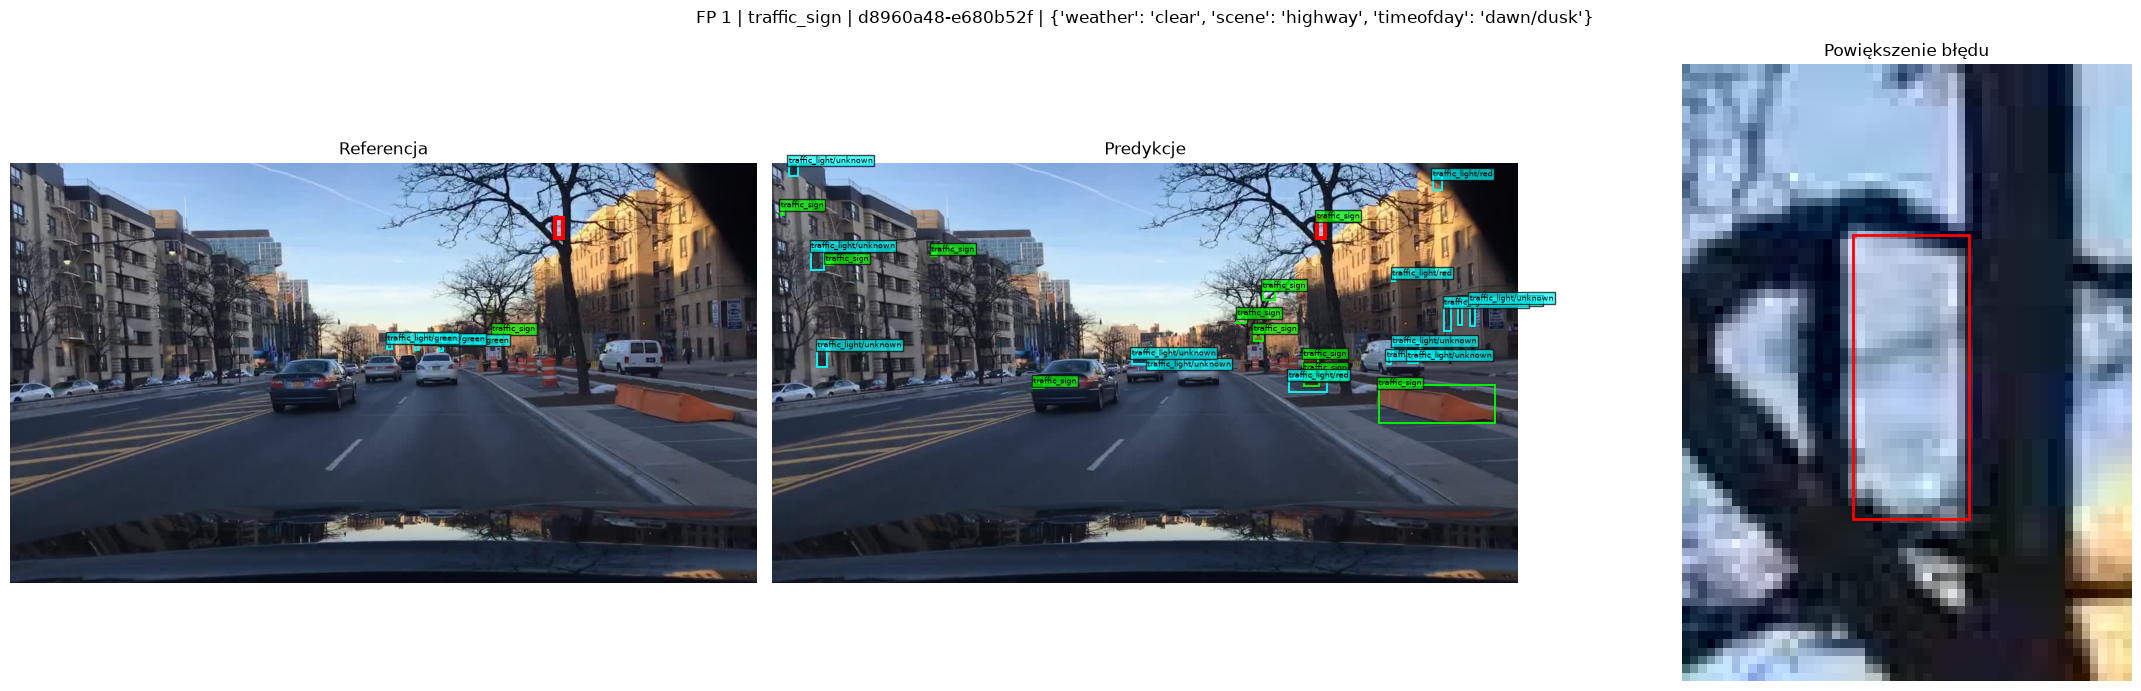

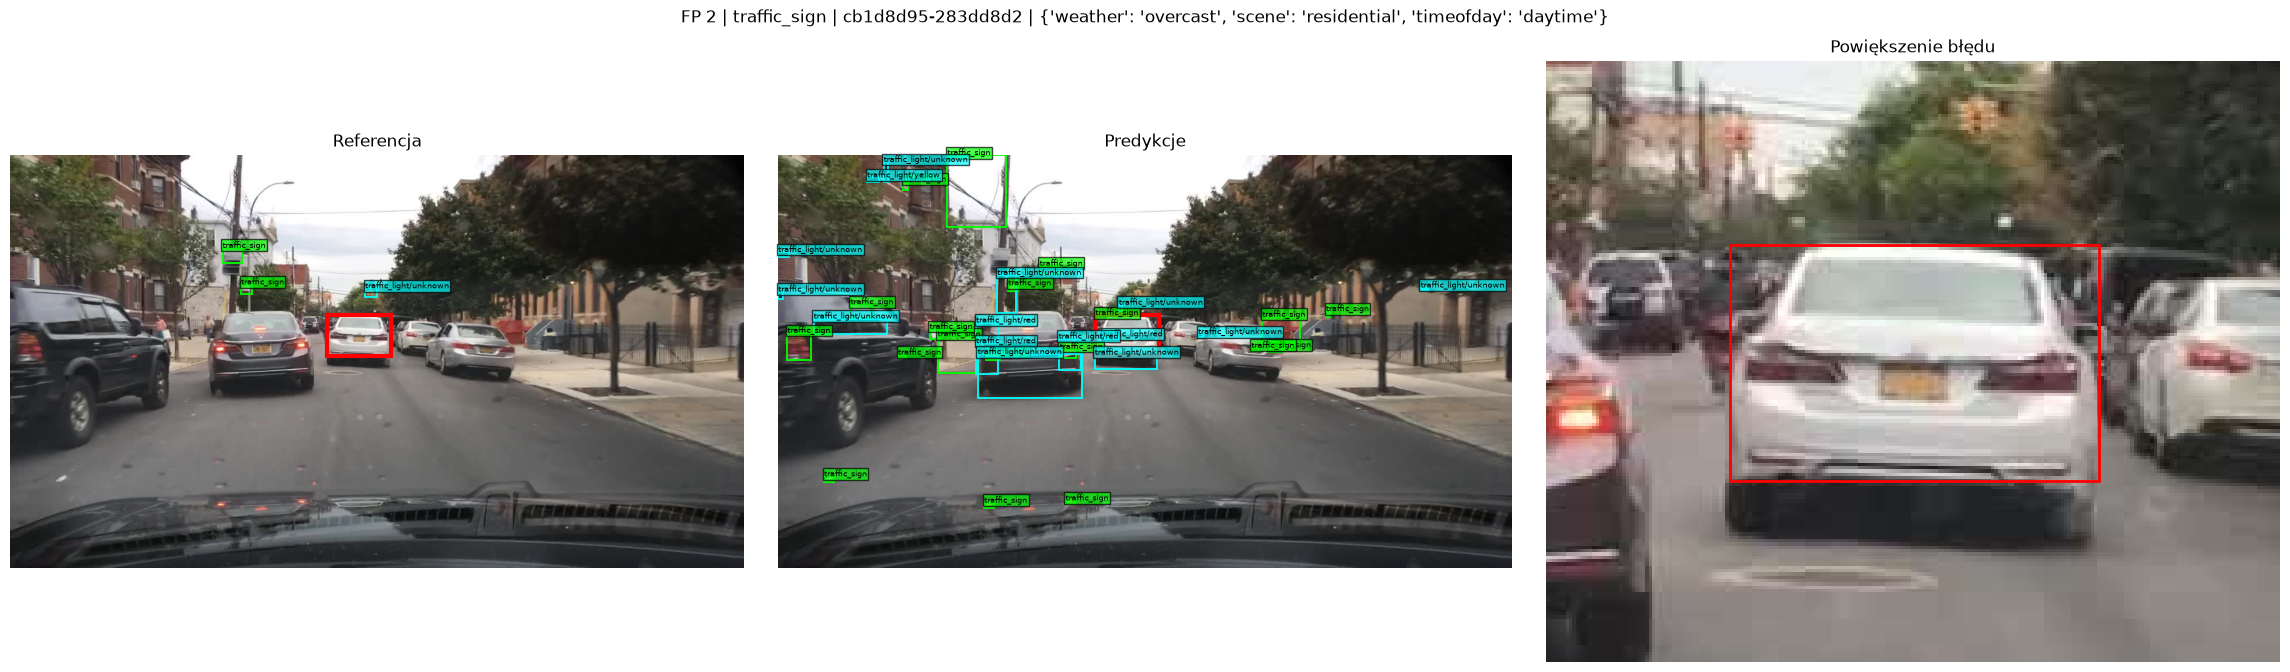

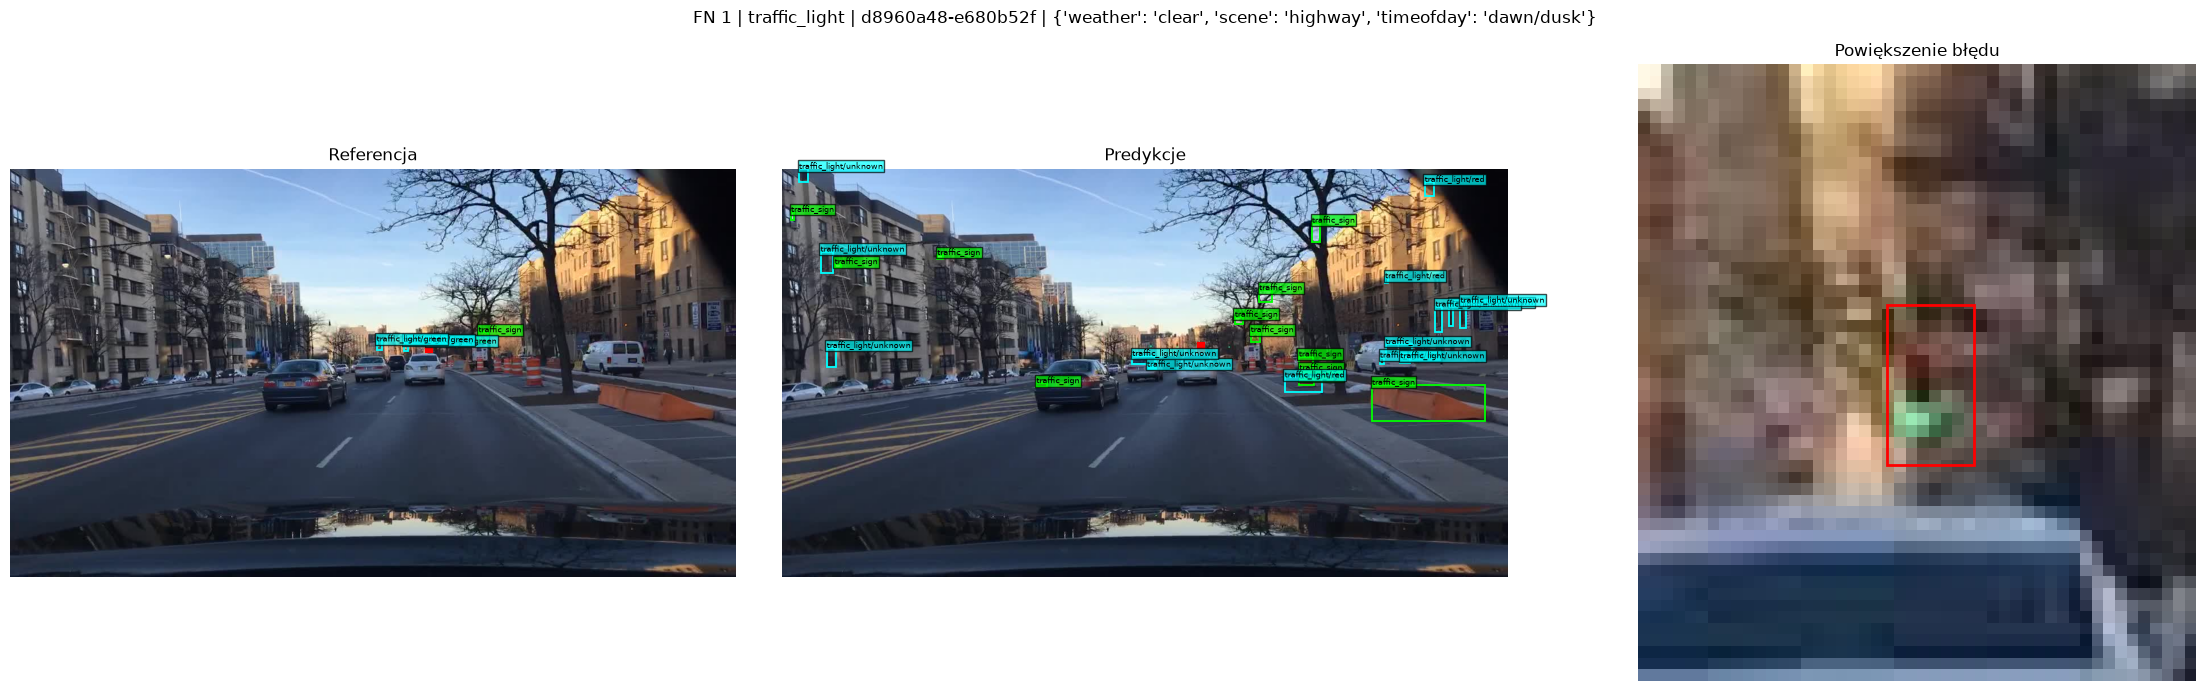

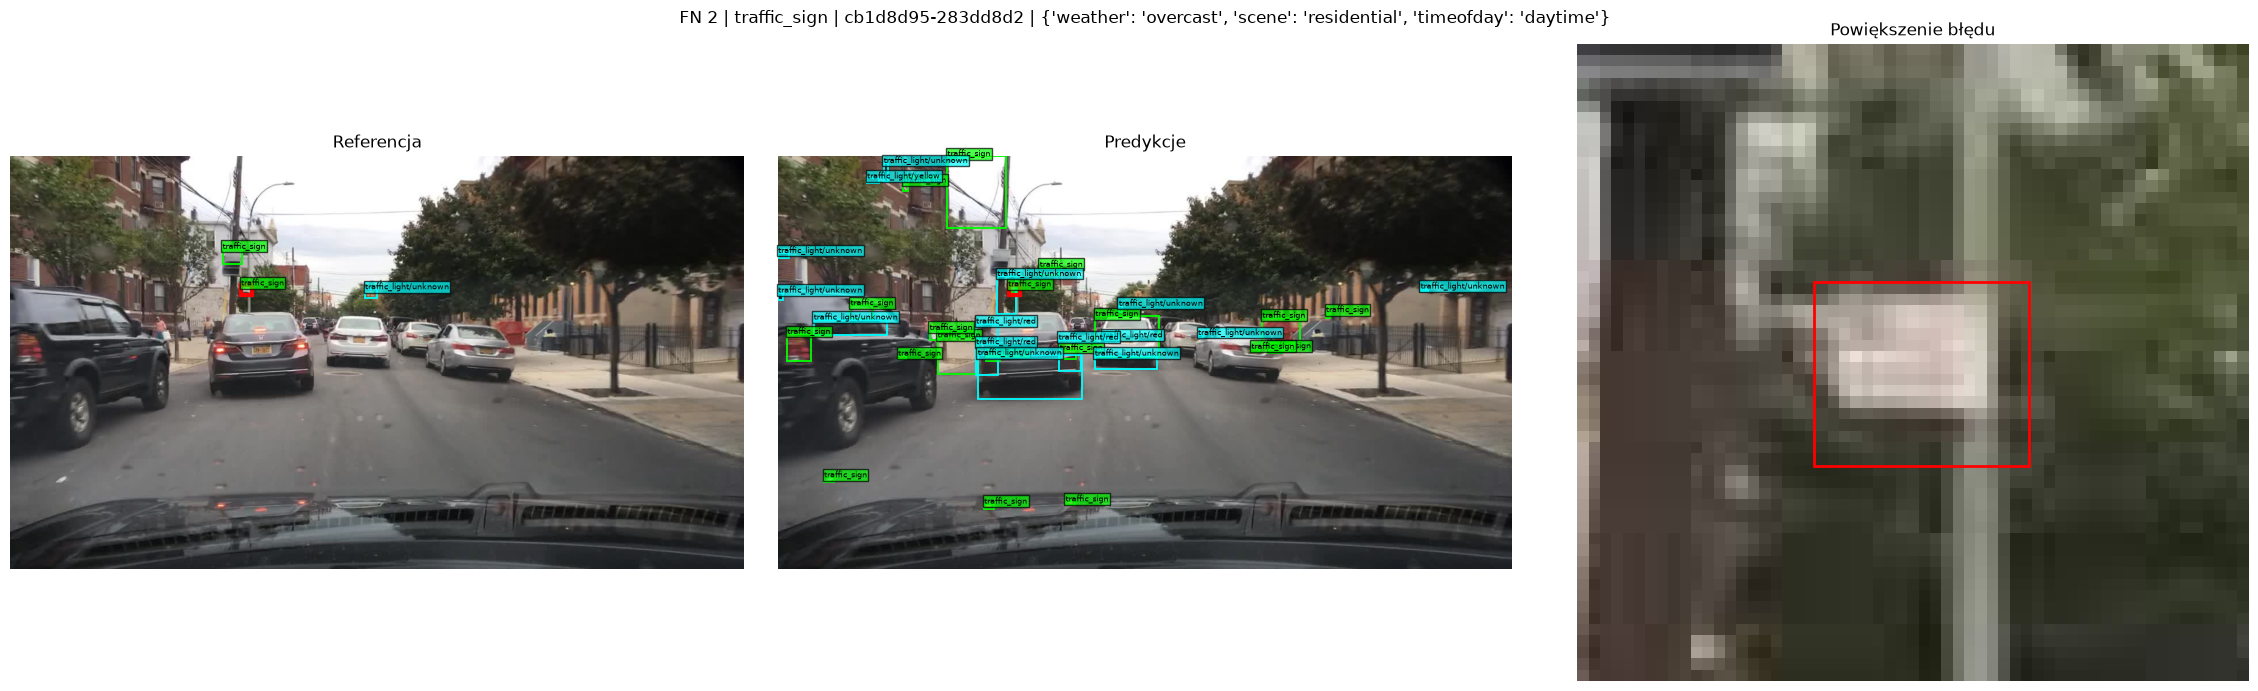

,id,type,class,box,figure,conditions
0,d8960a48-e680b52f,FP,traffic_sign,"[934, 95, 948, 129]",FP_1.png,"{'weather': 'clear', 'scene': 'highway', 'time..."
1,cb1d8d95-283dd8d2,FP,traffic_sign,"[553, 279, 664, 350]",FP_2.png,"{'weather': 'overcast', 'scene': 'residential'..."
2,d8960a48-e680b52f,FN,traffic_light,"[734.927131, 308.195249, 742.413655, 321.920543]",FN_1.png,"{'weather': 'clear', 'scene': 'highway', 'time..."
3,cb1d8d95-283dd8d2,FN,traffic_sign,"[402.299858, 225.449921, 421.19985, 241.649918]",FN_2.png,"{'weather': 'overcast', 'scene': 'residential'..."


In [8]:
from matplotlib.patches import Rectangle
lookup = {r['id']:r for r in splits['test']}
error_catalog = []
for kind in ['FP','FN']:
    available = [e for e in final['errors'] if e['type']==kind]
    chosen, used = [], set()
    for error in available:
        if error['id'] not in used:
            chosen.append(error); used.add(error['id'])
        if len(chosen)==2: break
    if len(chosen)<2:
        chosen += [e for e in available if e not in chosen][:2-len(chosen)]
    if len(chosen)<2: print(f'UWAGA: tylko {len(chosen)} przykładów {kind}.')
    for number, error in enumerate(chosen,1):
        r = lookup[error['id']]
        im = load_image(ROOT/r['image'])
        truth, attrs, _ = annotations(ROOT/r['label'], im.shape)
        predictions = final['predictions'][r['id']]
        fig, axes = plt.subplots(1,3, figsize=(23,7))
        draw(im, truth, 'Referencja', axes[0])
        draw(im, predictions, 'Predykcje', axes[1])
        x1,y1,x2,y2 = error['box']
        for ax in axes[:2]:
            ax.add_patch(Rectangle((x1,y1),x2-x1,y2-y1,fill=False,edgecolor='red',linewidth=3))
        pad = max(20, int(max(x2-x1,y2-y1)*.5))
        xx1,yy1 = max(0,int(x1)-pad),max(0,int(y1)-pad)
        xx2,yy2 = min(im.shape[1],int(x2)+pad),min(im.shape[0],int(y2)+pad)
        axes[2].imshow(cv2.cvtColor(im[yy1:yy2,xx1:xx2],cv2.COLOR_BGR2RGB))
        axes[2].add_patch(Rectangle((x1-xx1,y1-yy1),x2-x1,y2-y1,fill=False,edgecolor='red',linewidth=2))
        axes[2].set_title('Powiększenie błędu'); axes[2].axis('off')
        fig.suptitle(f"{kind} {number} | {error['class']} | {r['id']} | {attrs}")
        plt.tight_layout(); fig.savefig(EXP/f'{kind}_{number}.png', dpi=150); plt.show()
        error_catalog.append({**error,'figure':f'{kind}_{number}.png', 'conditions':attrs})
save_json(EXP/'illustrated_errors.json', error_catalog)
display(pd.DataFrame(error_catalog))

## Podsumowanie wyników

In [9]:
lines = [f"Podzbiór oficjalnego test: {len(splits['test'])} obrazów; cały podzbiór {N}; seed {SEED}; IoU >= 0.5."]
for row in final['metrics'].to_dict('records'):
    lines.append(f"{row['class']}: P={row['precision']:.3f}, R={row['recall']:.3f}, F1={row['F1']:.3f}; TP={row['TP']}, FP={row['FP']}, FN={row['FN']}.")
acc = final['color_accuracy']
lines.append(f"Kolor: accuracy={acc:.3f} na {final['matched_lights']} dopasowanych lampach." if acc is not None else 'Kolor: brak dopasowanych lamp, accuracy nieokreślona.')
lines.append('Metoda: heurystyki HSV + geometria; wyniki dotyczą podzbioru oficjalnego testu.')
report = '\n'.join(lines)
print(report)
(EXP/'facts_for_report.txt').write_text(report, encoding='utf-8')

Podzbiór oficjalnego test: 300 obrazów; cały podzbiór 1500; seed 42; IoU >= 0.5.
traffic_sign: P=0.028, R=0.160, F1=0.048; TP=156, FP=5428, FN=821.
traffic_light: P=0.008, R=0.027, F1=0.013; TP=21, FP=2476, FN=763.
Kolor: accuracy=0.762 na 21 dopasowanych lampach.
Metoda: heurystyki HSV + geometria; wyniki dotyczą podzbioru oficjalnego testu.


344

## Wnioski